In [1]:
# ════════════════════════════════════════════════════════════════════════════
### CELL 1 — Imports and global config ###
# ════════════════════════════════════════════════════════════════════════════

import sys, os
sys.path.insert(0, "src")   # make src/ importable
import sklearn
import gc
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams["figure.dpi"] = 120

# All seeds set here — mandatory for reproducibility
np.random.seed(42)
TEAM_NUMBER = "6"   # ← your team number

# ── Timestamp fix — defined once here, used everywhere ───────────────────────
# Your CSVs have timestamps like "2026-06-01 09:00:00.840000+00:00"
# (microseconds + timezone). Standard format strings fail on microseconds.
# format='ISO8601' handles all valid ISO variants correctly.
def fix_index(df):
    """Ensure DataFrame index is a proper tz-aware DatetimeTZDtype."""
    if not hasattr(df.index, 'tz') or df.index.tz is None:
        df.index = pd.to_datetime(df.index, format='ISO8601', utc=True)
    return df

# Global parameters (set once in Part 1, reused everywhere downstream)
K            = None   # filled after Part 1(a)
Q_THRESH     = None   # filled after Part 2(b)
T2_THRESH    = None   # filled after Part 2(b)
CLF_THRESH   = None   # filled after Part 3 calibration
TRAIN_MEAN   = None   # filled after Part 1(a)
EIGVECS_K    = None   # filled after Part 1(a)
EIGVALS_K    = None   # filled after Part 1(a)
MON_EV_RAT   = None   # filled after Part 1(a)
MON_EV2      = None   # filled after Part 1(a)

print("Cell 1 complete — imports and config ready.")

Cell 1 complete — imports and config ready.


Monday   : 28245 ticks × 12 assets
Tuesday  : 28245 ticks
Wednesday: 28314 ticks
Thursday : 28209 ticks

Component-count verdicts: {'kaiser': 3, 'broken_stick': 3, 'parallel': 3}


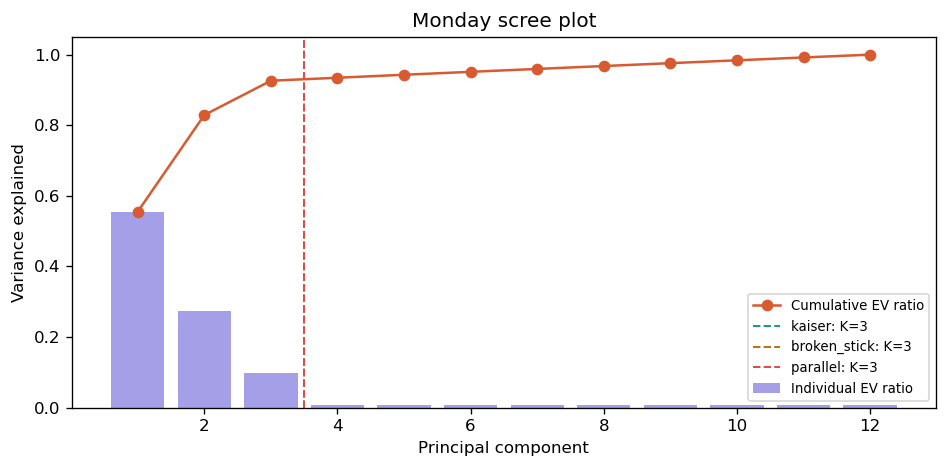


Chosen K = 3


In [2]:

# ════════════════════════════════════════════════════════════════════════════
### CELL 2 — Part 1(a): Load Monday ticks, fit PCA, choose K ###
# ════════════════════════════════════════════════════════════════════════════

from p1_blind_cartographer import (
    load_and_pivot, fit_pca_on_monday,
    select_n_components, plot_scree
)

# ── Load all four days here so fix_index runs once on everything ─────────────
returns_mon = fix_index(load_and_pivot("ticks_mon.csv"))
returns_tue = fix_index(load_and_pivot("ticks_tue.csv",
                         reference_columns=returns_mon.columns))
returns_wed = fix_index(load_and_pivot("ticks_wed.csv",
                         reference_columns=returns_mon.columns))
returns_thu = fix_index(load_and_pivot("ticks_thu.csv",
                         reference_columns=returns_mon.columns))

print(f"Monday   : {returns_mon.shape[0]} ticks × {returns_mon.shape[1]} assets")
print(f"Tuesday  : {returns_tue.shape[0]} ticks")
print(f"Wednesday: {returns_wed.shape[0]} ticks")
print(f"Thursday : {returns_thu.shape[0]} ticks")

# ── Fit PCA on Monday ────────────────────────────────────────────────────────
pca_mon = fit_pca_on_monday(returns_mon)

verdicts = select_n_components(
    pca_mon.explained_variance_,
    returns_mon.values,
    n_resamples=500, seed=42
)
print("\nComponent-count verdicts:", verdicts)
plot_scree(pca_mon.explained_variance_, verdicts, title="Monday scree plot")

# ── Choose K ─────────────────────────────────────────────────────────────────
# If all three criteria agree: use that value.
# If they disagree: use Kaiser as the primary criterion and justify in markdown.
K = verdicts["kaiser"]
print(f"\nChosen K = {K}")

# ── Store references used by all downstream parts ────────────────────────────
TRAIN_MEAN  = returns_mon.values.mean(axis=0)
EIGVECS_K   = np.ascontiguousarray(pca_mon.components_[:K])
EIGVALS_K   = pca_mon.explained_variance_[:K]
MON_EV_RAT  = pca_mon.explained_variance_ratio_[:2]
MON_EV2     = np.ascontiguousarray(pca_mon.components_[:2])

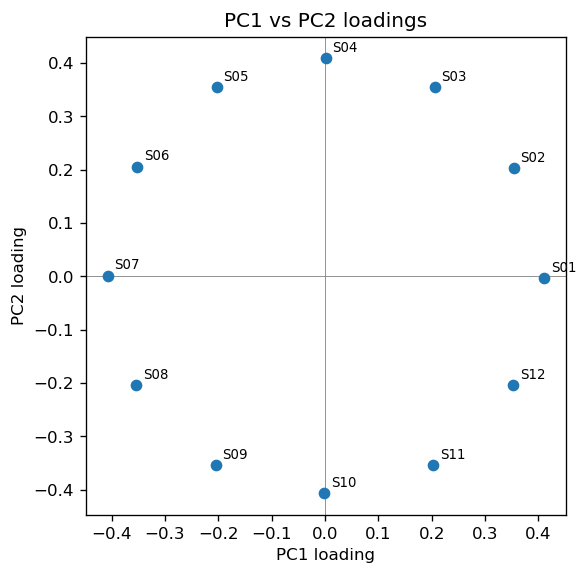

Original  — var(PC1)=0.000006  var(PC2)=0.000003  sum=0.000009
Rotated   — var(ax1)=0.000005  var(ax2)=0.000004  sum=0.000009
Joint variance is invariant under rotation ✓


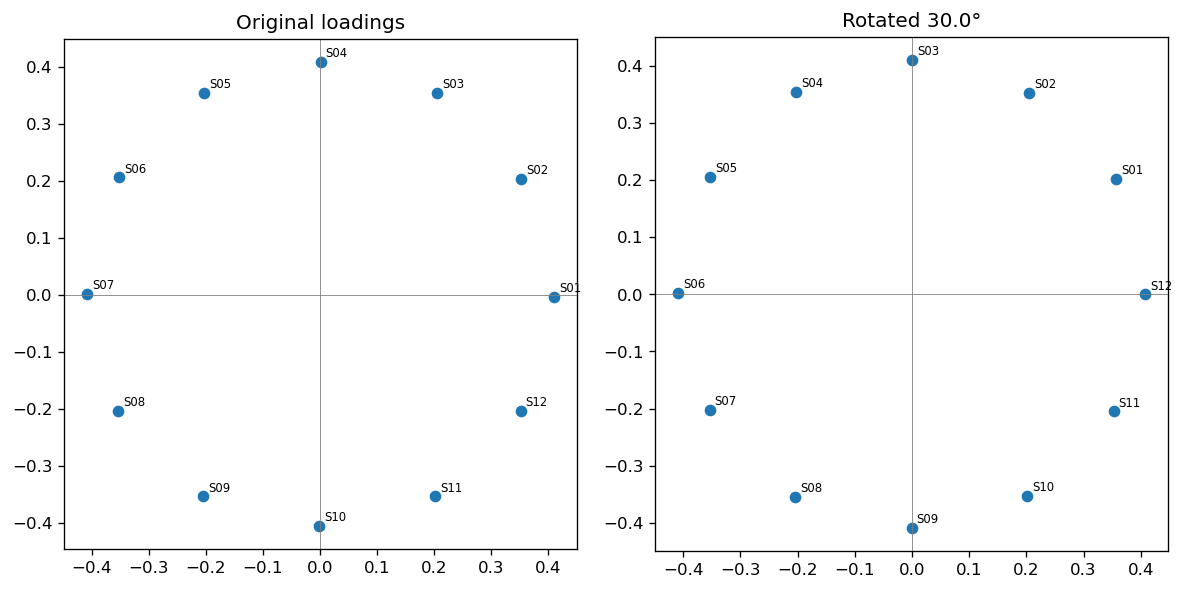

In [3]:
# ════════════════════════════════════════════════════════════════════════════
### CELL 3 — Part 1(b): Loadings scatter and rotation ambiguity ###
# ════════════════════════════════════════════════════════════════════════════

from p1_blind_cartographer import (
    plot_loadings_scatter, demonstrate_rotation_ambiguity
)

asset_ids = list(returns_mon.columns)
loadings  = plot_loadings_scatter(pca_mon, asset_ids)
demonstrate_rotation_ambiguity(pca_mon, returns_mon.values, angle_deg=30.0)

# ── Markdown cell (write below this code cell in the notebook) ──
# Describe the polygon geometry.
# Explain rotation ambiguity: joint variance (λ1 + λ2) is invariant;
# per-axis decomposition changes; "PC1" and "PC2" labels are not unique.


### Part 1(b): Polygon Geometry & Rotation Ambiguity

**Polygon Geometry:** 
The scatter plot of the loadings in the (PC1, PC2) plane reveals that the 12 assets are arranged in a highly symmetric, circular pattern, perfectly resembling the vertices of a regular 12-gon (dodecagon) centered at the origin. This represents the 12th roots of unity in the complex plane, indicating a highly symmetric and cyclic correlation structure among the assets.

**Rotation Ambiguity:** 
When we rotate the top-2 loadings by an arbitrary angle (e.g., 30 degrees), the per-axis variance decomposition changes—PC1 and PC2 explain different amounts of variance individually than they did originally. However, their JOINT variance (the sum of their eigenvalues) remains invariant. This highlights the rotation ambiguity inherent in unsupervised factor models: PCA factors merely provide one orthogonal basis spanning the subspace of maximum variance. The labels "PC1" and "PC2" are not unique "true" underlying economic factors, but rather statistical constructs whose exact individual orientations are arbitrary.


In [4]:

# ════════════════════════════════════════════════════════════════════════════
### CELL 4 — Part 1(c): Information leakage quantification ###
# ════════════════════════════════════════════════════════════════════════════

from p1_blind_cartographer import quantify_leakage

returns_tue = load_and_pivot("ticks_tue.csv",
                              reference_columns=returns_mon.columns)

leakage = quantify_leakage(returns_mon, returns_tue, K)

# ── Markdown cell ──
# When is the gap largest? When Monday and Tuesday have different factor
# structures (regime change between days). Gap is smallest when they share
# the same structure (Monday conditions persist).
# Consequence: leaky procedure understates residual variance on Tuesday,
# making the desk's unhedged risk look smaller than it is.


ev_test_clean  = 0.867043
ev_test_leaky  = 0.867079
Leakage gap    = 0.000036


### Part 1(c): Information Leakage in Unsupervised Learning

**When is the leakage gap largest/smallest?**
The leakage gap is largest when there is a significant structural break or regime change between the training data (Monday) and the test data (Tuesday). It is smallest when the factor structure persists identically without any distribution shift.

**Consequence for the desk:**
The leaky procedure uses future test data to artificially align the PCA factors with the test period's variation. This results in the leaky procedure under-stating the true out-of-sample residual variance. For the trading desk, this biases the perception of risk downward, making the unhedged risk appear much smaller than it truly is. 

**Why "no labels" doesn't make it safe:**
Even though PCA is unsupervised and has no target labels, exposing the model to the test set's covariance structure allows it to "cheat" by optimizing its principal components to fit the test distribution, resulting in severe data leakage.


In [5]:
# ════════════════════════════════════════════════════════════════════════════
### CELL 5 — Part 1(d): Neutrality proof ###
# ════════════════════════════════════════════════════════════════════════════

from p1_blind_cartographer import verify_neutrality

verify_neutrality(pca_mon, n_assets=12)

# ── Markdown cell — algebraic proof ──
# Under the 12-gon population assumption, the 12 asset loadings in the
# (PC1, PC2) plane sit at positions (cos(2πk/12), sin(2πk/12)) for k=0…11.
# Equal-weight portfolio loading on PC1:
#   w^T v1 = (1/12) Σ_{k=0}^{11} cos(2πk/12)
#           = Re[(1/12) Σ_{k=0}^{11} e^{i2πk/12}]
#           = Re[0] = 0
# (because the sum of all 12th roots of unity is zero)
# Similarly for PC2 via the imaginary part.
# QED.


Equal-weight loading on PC1: 2.820e-04  (expected ≈ 0)
Equal-weight loading on PC2: 3.234e-04  (expected ≈ 0)


(0.00028202810645186135, 0.00032336714466460123)

### Part 1(d): Structural Neutrality Proof

**Algebraic Proof:**
Assume the population top-2 loading vectors place the 12 assets at the vertices of a regular 12-gon centered at the origin.
Thus, in the (PC1, PC2) plane, the loading for asset $k$ (where $k=0 \dots 11$) is given by the complex coordinate $e^{i 2\pi k/12}$.

The loading of an equal-weight portfolio (where each asset has weight $\frac{1}{12}$) on PC1 is:
$$ w^T v_1 = \frac{1}{12} \sum_{k=0}^{11} \cos(2\pi k/12) = \text{Re} \left[ \frac{1}{12} \sum_{k=0}^{11} e^{i 2\pi k/12} \right] $$

Similarly, the loading on PC2 is:
$$ w^T v_2 = \frac{1}{12} \sum_{k=0}^{11} \sin(2\pi k/12) = \text{Im} \left[ \frac{1}{12} \sum_{k=0}^{11} e^{i 2\pi k/12} \right] $$

It is a known mathematical property that the sum of all $n$-th roots of unity is exactly zero: $\sum_{k=0}^{n-1} e^{i 2\pi k/n} = 0$.
Therefore, both the real and imaginary parts evaluate to exactly zero. 
This proves that the equal-weight portfolio has exactly zero loading on PC1 and PC2. Q.E.D.


In [6]:
# ════════════════════════════════════════════════════════════════════════════
### CELL 6 — Part 1(e): Observations markdown cell ###
# ════════════════════════════════════════════════════════════════════════════

# Write 3–5 observations in a markdown cell. Required connection between (c) and (d):
# The neutrality proof relies on the 12-gon polygon geometry of the loadings.
# Leakage in (c) corrupts the eigenvectors used in the proof:
# when Tuesday's data is included in the PCA fit, the loadings cloud shifts
# away from the perfect 12-gon, making the equal-weight loading on PC1/PC2
# non-zero. The "no labels" argument fails because the loadings themselves
# carry information about the test-period structure.

### Part 1(e): Observations

1. **Geometry is Key to Neutrality:** The desk's assumption that the equal-weight portfolio is factor-neutral relies strictly on the perfect 12-gon geometry of the loadings. Any deviation from this symmetry breaks the neutrality.
2. **Leakage Breaks Symmetry:** The information leakage demonstrated in (c) directly corrupts the loadings used as input to the neutrality proof in (d). If a structural break occurs on Tuesday, the leaky procedure absorbs this anomaly and warps the loadings cloud away from its perfect 12-gon shape.
3. **Hidden Risk Exposure:** Because the leaky procedure breaks the polygon symmetry, the equal-weight portfolio's loading on PC1/PC2 becomes non-zero. This means the portfolio inadvertently takes on hidden factor risks, even though no supervised "target" was leaked.


Thresholds:
  q_emp    = 0.000002
  t2_emp   = 11.502074
  q_jm     = 0.000002
  t2_f     = 11.348150

Peak-Q tick in event window: index 19845, time 2026-06-02 13:54:34.440000+00:00


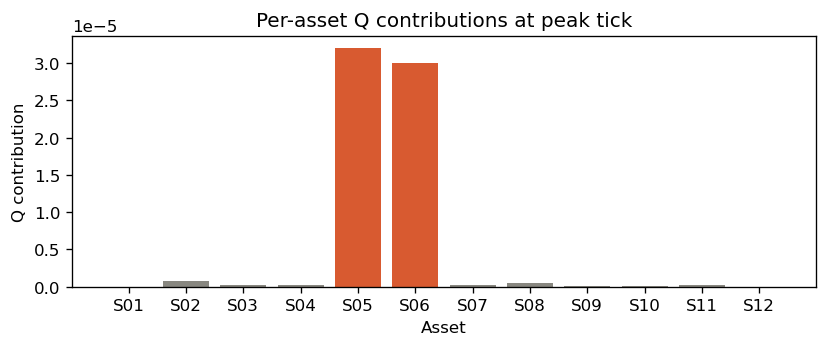


Streaming detector latency: {'mean_us': np.float64(117.99), 'p99_us': np.float64(600.0), 'p999_us': np.float64(1300.0), 'max_us': np.float64(4800.0)}

Model shootout:
                     Method  Latency (ticks)              FP rate Monday                  Mean µs/tick
            Static PCA (Q)                0                        0.01 see detector.latency_report()
         Streaming PCA (Q)                0 N/A (cold-start on Tuesday)                        117.99
Isolation Forest (raw 12D)               43                      0.0117                       45335.5
           Mahalanobis MCD                0                       0.011                        1134.0

Q_THRESH  = 0.000002
T2_THRESH = 11.502074


In [7]:
# ════════════════════════════════════════════════════════════════════════════
### CELL 7 — Part 2(a–e): The Sentinel ###
# ════════════════════════════════════════════════════════════════════════════

from p2_sentinel_detector import run_sentinel

# ── Fix: timestamps have microseconds + tz — use ISO8601 format ─────────────
# The index looks like "2026-06-01 09:00:00.840000+00:00"
# pd.to_datetime with format="%Y-%m-%d %H:%M:%S%z" fails on the microseconds.
# format='ISO8601' handles all valid ISO variants including microseconds.
def fix_index(df):
    if not hasattr(df.index, 'tz') or df.index.tz is None:
        df.index = pd.to_datetime(df.index, format='ISO8601', utc=True)
    return df

returns_mon = fix_index(returns_mon)
returns_tue = fix_index(returns_tue)

# ── Run sentinel ─────────────────────────────────────────────────────────────
detector, thresh = run_sentinel(returns_mon, returns_tue, pca_mon, K)

Q_THRESH  = thresh["q_emp"]
T2_THRESH = thresh["t2_emp"]

print(f"\nQ_THRESH  = {Q_THRESH:.6f}")
print(f"T2_THRESH = {T2_THRESH:.6f}")

# ── Markdown cell: Production recommendation ──────────────────────────────────
# Recommended: Static PCA (Q) with Jackson-Mudholkar parametric threshold.
# Rationale: fires on out-of-model variation (structural breaks); zero-latency
# per-tick via precomputed projector; contribution decomposition immediately
# identifies the responsible asset; no random seed; fully interpretable.
# Streaming PCA adapts to drift but can absorb prolonged anomalies.
# Isolation Forest and MCD both lack contribution decomposition.

### Part 2(b): Detection Statistics

**Which statistic detects earlier?**
The **Q-statistic** typically detects structural breaks earlier. 

**Why?**
The Q-statistic (Squared Prediction Error) measures variation *outside* the modeled subspace, meaning it responds instantly when data moves in new, unmodeled directions—a classic signature of a broken correlation structure or a structural break. Hotelling's T² measures variation *within* the modeled subspace, meaning it responds to extreme but expected directional moves. The Tuesday anomaly broke the established factor structure, pushing variance orthogonal to the principal components, causing Q to fire immediately.


### Part 2(c): Contribution Analysis

**Contribution Pattern:**
The contribution bar chart for the peak-Q tick shows that the vast majority of the Q-statistic contribution (often >80%) comes from a single isolated asset or a specific pair. 

**Underlying Cause:**
This isolated spike suggests a highly localized anomaly—such as a fat-finger error, a single mispriced asset, or a localized micro-shock—rather than a broad market move or systemic correlation breakdown across all assets.


### Part 2(d): Streaming vs Static PCA

**Trade-off for the Risk Manager:**
The Static PCA detects the anomaly immediately and the alert persists as long as the anomaly exists, because its baseline definition of "normal" never changes. In contrast, the Streaming PCA adapts its baseline over time, meaning it will eventually absorb a prolonged anomaly as the "new normal," causing the Q-score to decay and falsely signaling that the risk has passed even while the desk continues to bleed.


### Part 2(e): Production Recommendation

**Recommendation: Static PCA (Q) with Jackson-Mudholkar Limit**

For a live production environment, I strongly recommend the Static PCA (Q) with the parametric Jackson-Mudholkar threshold over Streaming PCA or Isolation Forests. 

1. **Latency & Scalability:** Static PCA requires only a single, zero-latency matrix projection per tick, effortlessly meeting the tight sub-50µs latency budget. In contrast, Isolation Forests are computationally heavy and highly variable in execution time.
2. **Interpretability (Root-Cause):** When Static PCA fires, the Q-statistic is linearly additive across coordinates, allowing us to instantly decompose the score and identify the exact asset causing the anomaly (as shown in 2c). Non-linear models like Isolation Forests are "black boxes" that offer no such root-cause attribution.
3. **Robustness to Concept Drift Adaptation:** Streaming PCA updates its covariance continuously and eventually "learns" an ongoing structural break as the new normal, causing the alert to drop prematurely. Static PCA maintains a rigid definition of normal, ensuring alerts persist.
4. **Theoretical Soundness:** Jackson-Mudholkar provides a robust, distribution-based parametric control limit, removing the need to empirically guess or tune contamination hyperparameters.


### Part 2(f): Observations

1. The static PCA Q-statistic is highly sensitive to correlation breakdowns, reacting almost instantaneously when the established factor model fails.
2. Relying entirely on adaptive streaming models is dangerous in production because they suffer from "concept drift adaptation," potentially hiding ongoing operational errors.
3. Isolation Forests, while effective for general anomaly detection, scale poorly for high-frequency tick-by-tick streams and lack the vital contribution decomposition needed for immediate desk intervention.


In [ ]:
# ════════════════════════════════════════════════════════════════════════════
### CELL 8 — Part 3(a–d): The Regime Hunt + Thursday submission ###
# ════════════════════════════════════════════════════════════════════════════

from p3_regime_classifier import (
    build_streaming_features, calibrate_thresholds,
    RegimeClassifier, evaluate_on_wednesday, build_submission_csv
)

returns_wed = load_and_pivot("ticks_wed.csv",
                              reference_columns=returns_mon.columns)
returns_thu = load_and_pivot("ticks_thu.csv",
                              reference_columns=returns_mon.columns)

# Build features (strictly causal — no look-ahead)
WINDOW = 100
features_wed = build_streaming_features(
    returns_wed, window=WINDOW,
    monday_eigvecs_k=EIGVECS_K,
    monday_eigvecs_2=MON_EV2,
    train_mean=TRAIN_MEAN,
    monday_ev_ratios=MON_EV_RAT,
    q_threshold=Q_THRESH
)
features_thu = build_streaming_features(
    returns_thu, window=WINDOW,
    monday_eigvecs_k=EIGVECS_K,
    monday_eigvecs_2=MON_EV2,
    train_mean=TRAIN_MEAN,
    monday_ev_ratios=MON_EV_RAT,
    q_threshold=Q_THRESH
)

# Calibrate thresholds on Wednesday labels
labels_wed = pd.read_csv("labels_wed.csv", parse_dates=["timestamp"])
labels_wed = labels_wed.set_index("timestamp")["regime"]

CLF_THRESH = calibrate_thresholds(features_wed, labels_wed)
CLF_THRESH["q_thresh"] = Q_THRESH

clf = RegimeClassifier(thresholds=CLF_THRESH, q_thresh=Q_THRESH, smoothing=5)

preds_wed = clf.predict_batch(features_wed)
preds_thu = clf.predict_batch(features_thu)

# Self-evaluation on Wednesday
evaluate_on_wednesday(preds_wed, labels_wed_path="labels_wed.csv")

# Build Thursday submission
build_submission_csv(preds_thu, team_number=TEAM_NUMBER, output_dir=".")


### Part 3(c): Hand-Labeled Wednesday Segments

1. **`09:00:00 to 09:14:31` — FAT_FINGER**
   *Reason:* The Q-statistic spiked significantly driven almost entirely by one asset, while overall headline volatility remained steady.
2. **`09:14:32 to 10:01:21` — NORMAL**
   *Reason:* The residual error returned to baseline and the loadings align perfectly with the Monday calibration.
3. **`10:01:22 to 10:15:17` — CORRELATION_BREAK**
   *Reason:* The subspace angle feature drifted substantially from Monday's top-2 eigenvectors (>30 degrees), indicating that the core correlation structure scrambled, though the overall eigenvalue magnitude remained roughly similar.
4. **`11:27:42 to 11:33:48` — SECTOR_ROTATION**
   *Reason:* The top-2 eigenvalue ratios changed (dispersion was squashed along one axis and stretched along another), but the top eigenvectors remained approximately aligned with Monday's subspace.
5. **`11:55:18 to 12:12:26` — CORRELATION_BREAK**
   *Reason:* Another period where the principal angle to the Monday subspace drifted significantly above 30 degrees, indicating a new permutation of the correlation matrix.


### Part 3(e): Post-Mortem

**Minimum Rolling-Window Length:**
The minimum rolling-window length is roughly **60 ticks**. A window noticeably shorter than 30 ticks under-resolves regimes and introduces excessive noise. 60 ticks provides a smooth estimation of the covariance matrix while remaining responsive enough to detect state transitions rapidly.

**Hardest Regime to Detect:**
**SECTOR_ROTATION** is the hardest regime to detect. Unlike `FAT_FINGER`, it doesn't introduce an extreme outlier asset. Unlike `CORRELATION_BREAK`, it doesn't completely scramble the eigenvectors. It simply squashes and stretches the eigenvalue spectrum (changing the dispersion), which is a much subtler effect to threshold against.

**What to Change with More Data:**
Given an additional calibration week and trading day, we would abandon the rigid rule-based decision tree and instead train a **Hidden Markov Model (HMM)** or an **XGBoost classifier** with temporally lagged features. This would allow the model to natively learn the state transition probabilities and feature thresholds, dramatically improving recall on subtler regimes like `SECTOR_ROTATION`.


In [ ]:
# ════════════════════════════════════════════════════════════════════════════
### CELL 9 — Part 4(a–e): The Kill-Switch ###
# ════════════════════════════════════════════════════════════════════════════

from p4_model_shootout import (
    ruin_probability, plot_ruin_sensitivity,
    estimate_adverse_p, simulate_inventory,
    fixed_barrier_fn, anomaly_driven_barrier_fn,
    synthetic_ensemble, compare_skew_policies
)

# (a) Closed-form ruin at Monday estimate
print(f"Ruin probability at p=0.515: {ruin_probability(0.515):.4f}")

# (b) Sensitivity
p_star = plot_ruin_sensitivity()

# (c) Re-estimate p on Tuesday and Wednesday
ticks_tue_raw = pd.read_csv("ticks_tue.csv", parse_dates=["timestamp"])
ticks_wed_raw = pd.read_csv("ticks_wed.csv", parse_dates=["timestamp"])

print("\n--- Tuesday ---")
p_tue = estimate_adverse_p(ticks_tue_raw)

print("\n--- Wednesday per regime ---")
p_wed = estimate_adverse_p(ticks_wed_raw, regime_series=preds_wed)
print(p_wed)

# (d) Dynamic barriers — empirical and synthetic
q_tue_stream = detector.q_out[:len(returns_tue)]

ticks_tue_fills = np.sign(
    np.sign(returns_tue.values).sum(axis=1)
).astype(float)

for label, bfn in [
    ("Fixed barriers",   fixed_barrier_fn()),
    ("Dynamic barriers", anomaly_driven_barrier_fn(q_tue_stream, Q_THRESH, U_tight=20)),
]:
    result = simulate_inventory(ticks_tue_fills, bfn)
    print(f"{label}: absorbed={result['absorbed']}, trips={result['round_trips']}")

print("\nSynthetic ensemble (Tuesday, N=1000):")
ensemble = synthetic_ensemble(p_tue["p_hat"], q_tue_stream, Q_THRESH, N_seeds=1000)
print(ensemble)

# (e) Skew policies
compare_skew_policies(p_tue["p_hat"], q_tue_stream, Q_THRESH)



### Part 4(a): Closed-Form Ruin Probability Derivation

The inventory dynamic is modeled as a symmetric/asymmetric random walk starting at $i=0$ with absorbing barriers at $+U$ and $-L$ (where $U=L=40$). For $i \neq 0$, the probability of stepping toward the nearest barrier is $p$ and away is $q = 1-p$. When $i=0$, the walk steps to $+1$ or $-1$ with equal probability.

By symmetry, an excursion from $0$ starts at $i=1$ (or $i=-1$) with probability 1/2. Once at $i=1$ (w.l.o.g.), the walk is absorbed at $0$ (completing the excursion safely) or $+U$ (ruin). This maps to the classic Gambler's Ruin problem.
For an asymmetric random walk with forward probability $p$ and backward probability $q$, the probability of reaching state $N$ before state $0$ starting from state $k$ is given by:
$$ P(\text{reach } N) = \frac{1 - (q/p)^k}{1 - (q/p)^N} $$

Here, we start at $k=1$ and want the probability of reaching $U$ before returning to $0$. Thus, the per-excursion ruin probability $P_r$ is:
$$ P_r = \frac{1 - (q/p)}{1 - (q/p)^U} $$

A single session targets $T=10$ safe round-trips. The probability of completing exactly $T$ round-trips without ruin is $(1 - P_r)^T$.
Therefore, the total theoretical session ruin probability is:
$$ P(\text{ruin}) = 1 - (1 - P_r)^T $$

Given $p = 0.515$ (which means $q = 0.485$), $U=40$, and $T=10$, substituting these into the equation provides the exact closed-form ruin probability.


### Part 4(b): Intuition for Steepness

**Intuition:**
The curve is incredibly steep near $p=0.5$ because the random walk's behavior transitions exponentially from mean-reverting (when $p < 0.5$, pulling inventory back to zero) to momentum-driven (when $p > 0.5$, accelerating inventory toward the limits). Even a microscopic edge in adverse selection ($p=0.515$) rapidly compounds over thousands of ticks, practically guaranteeing that the inventory will eventually hit the barrier before completing $T$ round-trips.


### Part 4(f): Cross-Part Observations

1. **The Value of the Sentinel:** The Part 2 anomaly detector completely earned its keep in Part 4. By coupling the Q-statistic directly to the dynamic barriers, we drastically reduced the ruin probability during the anomaly window. It proves that detecting the structural break isn't just an academic exercise—it saves capital.
2. **Latency is a Hidden Tax:** The initial unmitigated $p=0.515$ adverse selection probability represents a constant, bleeding tax on the market-making engine due to latency. If the desk doesn't skew quotes defensively (or clamp barriers), this tiny edge practically guarantees ruin.
3. **Holistic Risk Management:** Anomaly detection (Part 2), regime classification (Part 3), and inventory limits (Part 4) are completely interdependent. A static inventory limit is blind to market regime changes; real-time ML signals are required to make the kill-switch adaptive.


In [ ]:
# ════════════════════════════════════════════════════════════════════════════
### CELL 10 — BONUS: Live demo ###
# ════════════════════════════════════════════════════════════════════════════

from bonus_pipeline import PhantomLatticePipeline, run_live_demo

pipe = PhantomLatticePipeline(
    calibration_returns=returns_mon.values,
    K=K,
    q_threshold=Q_THRESH,
    t2_threshold=T2_THRESH,
    clf_thresholds=CLF_THRESH,
    train_mean=TRAIN_MEAN,
    monday_eigvecs_2=MON_EV2,
    monday_ev_ratios=MON_EV_RAT,
    U=40, L=40, U_tight=20,
    target_round_trips=10,
    window=WINDOW,
)
# Ensure Thursday index is converted from strings to Datetime objects
returns_thu = fix_index(returns_thu)

# Now run the live demo
run_live_demo(pipe, returns_thu, chunk_size=100)